# nb3 — Quartz/Si experimental fit with Adam, sensitivity matrix, Cramér–Rao bounds and the two-phase loss landscape

Data: `data/Reference_15min_nitrogen.txt` (reference) and `data/Quartz_Si_15min_nitrogen.txt` (sample),
2425 points, dt = 33 fs.  Two-layer model quartz / Si, parameters $p = (n_1,\kappa_1,d_1,n_2,\kappa_2,d_2)$,
$\tilde n = n - i\kappa$.

Protocol (exactly as in `QuartzSI_loss_landscape_Adam_visualization.ipynb`, but in float64):
loss = MAE + log-cosh of the time-domain residual; Adam, lr $10^{-4}$ on multiplicative factors $u = p/p^{(0)}$;
20 000 iterations; three starts ($n_1$ = 1.982 / 1.900 / 2.010, $d_1$ = 1000 / 900 / 900 µm, $\kappa_1$ = 0.0071,
Si start 3.40 / 0.0054 / 400 µm); the trajectory is recorded at every iteration.

Then: sensitivity matrix $G = J^\top J/L$ in scaled coordinates at the best optimum, singular values,
eigenvectors, correlation coefficients; Cramér–Rao bounds $\mathrm{cov} = \sigma^2 (J^\top J)^{-1}$ with
$\sigma$ = pre-pulse std of the sample trace (step by step for the $\kappa_2$-sign argument);
the softplus-constrained fit ($\kappa \ge 0$); the two-phase PCA landscape.

Outputs: `figs/fig3_exp_fit.*`, `figs/fig4_adam_two_phase.*`, `figs/fig_sensitivity.*`, `results/nb3.json`,
`results/nb3_trajectories.npz` (trajectories + PCA planes, used by nb4).

In [1]:
import sys, os, json, time
sys.path.insert(0, '../code')
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

torch.set_num_threads(int(os.environ.get('NB_THREADS', 2)))
torch.set_default_dtype(torch.float64)

import loss_landscape_viz as lv          # PCA planes, phase split, landscape primitives (sets its own rcParams)
from quartzsi_model import QuartzSiProblem, STARTS, PARAM_NAMES, PARAM_TEX, DT
import paperstyle as ps
ps.apply()                               # paper rcParams win
lv.LANDSCAPE_CMAP = ps.LANDSCAPE_CMAP
lv.TRAJ_COLORS[:3] = [ps.ROLE['start1'], ps.ROLE['start2'], ps.ROLE['start3']]

RUN_FULL = False                         # False -> load results/nb3_cache.npz if present (skips the 4 x 20 000-iteration fits)
CACHE = '../results/nb3_cache.npz'
os.makedirs('../figs', exist_ok=True); os.makedirs('../results', exist_ok=True)

## 1. Data and model

In [2]:
P = QuartzSiProblem('../data/Reference_15min_nitrogen.txt', '../data/Quartz_Si_15min_nitrogen.txt', prepulse_ps=10.0)
L, deltat, t_r = P.L, P.deltat, P.t_r
x_exp, true_x_exp = P.x_exp, P.true_x_exp
sigma = P.sigma
print(f"L = {L}, dt = {deltat*1e15:.1f} fs, window = {t_r[-1]:.1f} ps")
print(f"pre-pulse (t < {P.prepulse_ps:.0f} ps) std of the sample trace: sigma = {sigma:.3e}; sample peak {np.abs(true_x_exp).max():.3f}")
initial_loss = [P.loss_np(s) for s in STARTS]
print('loss at the three starts:', np.array2string(np.array(initial_loss), precision=4))

L = 2425, dt = 33.0 fs, window = 80.0 ps
pre-pulse (t < 10 ps) std of the sample trace: sigma = 2.901e-04; sample peak 2.295
loss at the three starts: [0.0466 0.0739 0.0304]


## 2. Adam fit protocol (multiplicative factors, MAE + log-cosh, lr 1e-4, 20 000 iterations)

In [3]:
N_ITERS, LR = 20000, 1e-4
BETA_SOFTPLUS = 5.0

def adam_fit(p0, n_iters=N_ITERS, lr=LR, constrain_kappa=False, beta=BETA_SOFTPLUS, print_step=2000, label=''):
    """Adam on u = p / p0 (all start at 1).  constrain_kappa: κ_j = κ_j^(0) softplus(β θ_j)/softplus(β), θ_j starts at 1,
    so that κ ≥ 0 by construction and the start is unchanged.  Returns params [N, 6], loss [N] (recorded every iteration,
    exactly as in the reference notebook: entry 0 = start, entry i = after i Adam steps)."""
    p0 = torch.tensor(np.asarray(p0, float), dtype=DT)
    u = torch.ones(6, dtype=DT, requires_grad=True)
    opt = torch.optim.Adam([u], lr=lr)
    sp_beta = torch.nn.functional.softplus(torch.tensor(beta, dtype=DT))

    def params():
        if not constrain_kappa:
            return u * p0
        fac = torch.where(torch.tensor([False, True, False, False, True, False]),
                          torch.nn.functional.softplus(beta * u) / sp_beta, u)
        return fac * p0

    params_hist, loss_hist = [], []
    p = params(); loss = P.loss_torch(p)
    params_hist.append(p.detach().numpy().copy()); loss_hist.append(loss.item())
    t0 = time.time()
    for i in range(1, n_iters):
        opt.zero_grad()
        loss.backward()
        opt.step()
        p = params(); loss = P.loss_torch(p)
        params_hist.append(p.detach().numpy().copy()); loss_hist.append(loss.item())
        if (i + 1) % print_step == 0 or i == n_iters - 1:
            q = params_hist[-1]
            print(f"[{label}] it {i+1:6d}  n1={q[0]:.6f} k1={q[1]:.3e} d1={q[2]*1e6:.2f}um  n2={q[3]:.6f} k2={q[4]:+.3e} d2={q[5]*1e6:.2f}um  loss={loss.item():.6e}", flush=True)
    wall = time.time() - t0
    return np.array(params_hist), np.array(loss_hist), wall

## 3. Three unconstrained starts and the softplus-constrained fit from start 1

In [4]:
if RUN_FULL or not os.path.exists(CACHE):
    runs = []
    for k, s in enumerate(STARTS):
        pr, lo, wall = adam_fit(s, label=f'start {k+1}')
        runs.append((pr, lo, wall))
        print(f"start {k+1}: {N_ITERS} iterations in {wall:.0f} s ({1e3*wall/N_ITERS:.1f} ms/it), final loss {lo[-1]:.6e}")
    pr_c, lo_c, wall_c = adam_fit(STARTS[0], constrain_kappa=True, label='start 1, softplus')
    print(f"constrained: {N_ITERS} iterations in {wall_c:.0f} s, final loss {lo_c[-1]:.6e}")
    np.savez(CACHE, **{f'traj{k}_params': r[0] for k, r in enumerate(runs)}, **{f'traj{k}_loss': r[1] for k, r in enumerate(runs)},
             walls=np.array([r[2] for r in runs]), constrained_params=pr_c, constrained_loss=lo_c, wall_c=wall_c)
else:
    z = np.load(CACHE)
    runs = [(z[f'traj{k}_params'], z[f'traj{k}_loss'], float(z['walls'][k])) for k in range(3)]
    pr_c, lo_c, wall_c = z['constrained_params'], z['constrained_loss'], float(z['wall_c'])
    print('loaded cache', CACHE)

trajs = [{'params': r[0], 'loss': r[1], 'label': f'Start {k+1}'} for k, r in enumerate(runs)]
walls = [r[2] for r in runs]
fits = np.array([t['params'][-1] for t in trajs]); final_losses = np.array([t['loss'][-1] for t in trajs])
print('\nfinal parameters per start (n1, k1, d1[um], n2, k2, d2[um], loss):')
for k in range(3):
    f = fits[k]; print(f"  start {k+1}: {f[0]:.4f} {f[1]:.5f} {f[2]*1e6:.1f} {f[3]:.4f} {f[4]:+.5f} {f[5]*1e6:.1f}  {final_losses[k]:.4e}")
f = pr_c[-1]
print(f"  softplus:  {f[0]:.4f} {f[1]:.5f} {f[2]*1e6:.1f} {f[3]:.4f} {f[4]:+.5f} {f[5]*1e6:.1f}  {lo_c[-1]:.4e}")

loaded cache ../results/nb3_cache.npz

final parameters per start (n1, k1, d1[um], n2, k2, d2[um], loss):
  start 1: 1.9639 0.00541 994.3 3.4478 -0.00144 381.4  4.4522e-03
  start 2: 1.9637 0.00540 994.4 3.4488 -0.00140 381.3  4.4528e-03
  start 3: 1.9639 0.00541 994.2 3.4473 -0.00146 381.5  4.4518e-03
  softplus:  1.9595 0.00478 996.6 3.4681 +0.00011 379.1  4.4646e-03


## 4. Best optimum, scaled coordinates, sensitivity matrix $G = J^\top J / L$

In [5]:
ref, scale = lv.reference_and_scale(trajs)      # ref = lowest-loss point of all trajectories; scale = mean initial guess (nominal values)
best_start = int(np.argmin([t['loss'].min() for t in trajs]))
loss_ref = P.loss_np(ref); mae_ref = P.mae_np(ref)
print('optimum (best of the three runs, start', best_start + 1, '):', dict(zip(PARAM_NAMES, np.round(ref, 6))))
print(f'loss {loss_ref:.6e}, MAE {mae_ref:.4e} = {mae_ref/sigma:.1f} sigma')
print('scale (nominal values):', dict(zip(PARAM_NAMES, scale)))

J = P.jacobian(ref, scale)                      # [L, 6], scaled coordinates, float64
G = J.T @ J / L
w, V = np.linalg.eigh(G); order = np.argsort(-w); w, V = w[order], V[:, order]
sv = np.sqrt(np.clip(w, 0, None))
dG = np.sqrt(np.diag(G)); corr = G / np.outer(dG, dG)
np.set_printoptions(precision=4, suppress=True)
print('\nsingular values sqrt(eig G):', sv)
print('sigma1/sigma6 =', sv[0] / sv[-1])
print('eigenvectors (columns, well -> poorly constrained):'); print(V)
print('correlation matrix of G (n1 k1 d1 n2 k2 d2):'); print(corr)
print('diag sqrt(G) (RMS pulse change per unit fractional step):', dG)

optimum (best of the three runs, start 3 ): {'n1': np.float64(1.963902), 'k1': np.float64(0.005411), 'd1': np.float64(0.000994), 'n2': np.float64(3.447614), 'k2': np.float64(-0.001458), 'd2': np.float64(0.000381)}
loss 4.451584e-03, MAE 4.3798e-03 = 15.1 sigma
scale (nominal values): {'n1': np.float64(1.9639999999999997), 'k1': np.float64(0.0070999999999999995), 'd1': np.float64(0.0009333333333333333), 'n2': np.float64(3.4), 'k2': np.float64(0.005399999999999999), 'd2': np.float64(0.0004)}



singular values sqrt(eig G): [8.6647 1.5406 0.6895 0.0733 0.0192 0.0016]
sigma1/sigma6 = 5455.817117615689
eigenvectors (columns, well -> poorly constrained):
[[-0.6912 -0.5022  0.4534  0.2499 -0.0445 -0.0051]
 [-0.      0.0002 -0.0004 -0.1714 -0.932  -0.3194]
 [-0.3592 -0.3746 -0.8104 -0.2674  0.0476  0.0055]
 [-0.4877  0.5145  0.2046 -0.6645  0.1175  0.0137]
 [ 0.      0.0001 -0.0001 -0.0366 -0.3179  0.9474]
 [-0.3943  0.5854 -0.3095  0.6274 -0.1107 -0.013 ]]
correlation matrix of G (n1 k1 d1 n2 k2 d2):
[[ 1.      0.      0.9729  0.9509 -0.0114  0.9201]
 [ 0.      1.      0.0071  0.0114  0.9509  0.0002]
 [ 0.9729  0.0071  1.      0.9124 -0.0061  0.899 ]
 [ 0.9509  0.0114  0.9124  1.      0.      0.9927]
 [-0.0114  0.9509 -0.0061  0.      1.     -0.0058]
 [ 0.9201  0.0002  0.899   0.9927 -0.0058  1.    ]]
diag sqrt(G) (RMS pulse change per unit fractional step): [6.0468 0.0219 3.2143 4.3017 0.0068 3.5399]


## 5. Cramér–Rao bounds and the sign of $\kappa_2$, step by step

With Gaussian noise of standard deviation $\sigma$ on every sample and an exact model, the covariance of the
least-squares estimate of the scaled parameters is $\mathrm{cov}(\hat x) = \sigma^2 (J^\top J)^{-1}$; the
physical bound is $\delta p_i = \sigma\,\sqrt{[(J^\top J)^{-1}]_{ii}}\;\mathrm{scale}_i$.

In [6]:
JtJ = J.T @ J
JtJ_inv = np.linalg.inv(JtJ)
col_norms = np.linalg.norm(J, axis=0)                       # ||J_i|| in scaled units
col_norms_phys = col_norms / scale                          # per unit physical change
cr_scaled = sigma * np.sqrt(np.diag(JtJ_inv))               # bound on x_i (fraction of nominal)
cr_phys = cr_scaled * scale                                 # bound on p_i
corr_cov = JtJ_inv / np.sqrt(np.outer(np.diag(JtJ_inv), np.diag(JtJ_inv)))
k2_fit = ref[4]; k2_bound = cr_phys[4]
print(f"sigma (pre-pulse std, sample trace)     = {sigma:.3e}")
print("||J_i|| (scaled, per unit fractional step):", col_norms)
print("||J_i|| (per unit physical step)          :", col_norms_phys)
print("diag (J^T J)^-1                           :", np.diag(JtJ_inv))
print("Cramer-Rao bound, fraction of nominal     :", cr_scaled)
print("Cramer-Rao bound, physical units          :", cr_phys)
print(f"\nkappa_2: fitted {k2_fit:+.4e}, CR bound {k2_bound:.2e}  ->  |kappa_2| / bound = {abs(k2_fit)/k2_bound:.0f}")
print(f"kappa_1: fitted {ref[1]:+.4e}, CR bound {cr_phys[1]:.2e}  ->  {100*cr_phys[1]/ref[1]:.2f} % of its value")
print(f"d_1 bound {cr_phys[2]*1e9:.1f} nm, d_2 bound {cr_phys[5]*1e9:.1f} nm, n_1 bound {cr_phys[0]:.1e}, n_2 bound {cr_phys[3]:.1e}")
print(f"\nloss with kappa_2 >= 0 enforced (softplus fit, everything else re-optimised): {lo_c[-1]:.6e}"
      f"  vs unconstrained {loss_ref:.6e}: increase {100*(lo_c[-1]/loss_ref-1):.3f} %")
# residual-based noise check: is the residual white at the noise level?
resid = true_x_exp - P.ysim_np(ref)
print(f"residual: MAE {np.mean(np.abs(resid)):.3e} ({np.mean(np.abs(resid))/sigma:.1f} sigma), RMS {np.sqrt(np.mean(resid**2)):.3e}, "
      f"pre-pulse RMS {np.sqrt(np.mean(resid[t_r < 10]**2)):.3e}")

sigma (pre-pulse std, sample trace)     = 2.901e-04
||J_i|| (scaled, per unit fractional step): [297.7699   1.0764 158.2854 211.8339   0.3364 174.3185]
||J_i|| (per unit physical step)          : [   151.614     151.6085 169591.4644     62.3041     62.3033 435796.3479]
diag (J^T J)^-1                           : [  0.0116  17.6518   0.0137   0.0803 146.8645   0.0717]
Cramer-Rao bound, fraction of nominal     : [0.     0.0012 0.     0.0001 0.0035 0.0001]
Cramer-Rao bound, physical units          : [0.0001 0.     0.     0.0003 0.     0.    ]

kappa_2: fitted -1.4578e-03, CR bound 1.90e-05  ->  |kappa_2| / bound = 77
kappa_1: fitted +5.4112e-03, CR bound 8.65e-06  ->  0.16 % of its value
d_1 bound 31.6 nm, d_2 bound 31.1 nm, n_1 bound 6.1e-05, n_2 bound 2.8e-04

loss with kappa_2 >= 0 enforced (softplus fit, everything else re-optimised): 4.464560e-03  vs unconstrained 4.451584e-03: increase 0.291 %
residual: MAE 4.380e-03 (15.1 sigma), RMS 1.199e-02, pre-pulse RMS 4.094e-04


## 6. Two-phase PCA landscape (Phase I: per-start planes in curvature-normalised coordinates; Phase II: shared plane)

In [7]:
FRAC, RES = 0.05, 61
b = lv.split_phases(trajs, FRAC)
N = max(len(t['loss']) for t in trajs)
metric = lv.curvature_metric(G)
print(f'phase boundary at iteration {b} of {N}  (fraction of iterations in Phase II: {(N-b)/N:.3f})')
t0 = time.time()
planes1, grids1 = [], []
for k, t in enumerate(trajs):
    p = lv.pca_plane(trajs, ref, scale, which=k, iter_range=(0, b + 1), weight_late=False, metric=metric)
    planes1.append(p); grids1.append(lv.evaluate_plane(P.loss_np, p, trajs=[t], res=RES, verbose=False))
plane2 = lv.pca_plane(trajs, ref, scale, iter_range=(b, N))
grid2 = lv.evaluate_plane(P.loss_np, plane2, trajs=trajs, res=RES, verbose=False)
print(f'4 planes at {RES}x{RES} in {time.time()-t0:.0f} s')
for k, p in enumerate(planes1):
    print(f'Phase I plane, start {k+1}: explained {100*p["explained"][0]:.1f} % + {100*p["explained"][1]:.1f} %;  PC1 = {lv._fmt_dir(p["u"])},  PC2 = {lv._fmt_dir(p["v"])}')
print(f'Phase II plane: explained {100*plane2["explained"][0]:.1f} % + {100*plane2["explained"][1]:.1f} %;  PC1 = {lv._fmt_dir(plane2["u"])},  PC2 = {lv._fmt_dir(plane2["v"])}')

phase boundary at iteration 1615 of 20000  (fraction of iterations in Phase II: 0.919)


4 planes at 61x61 in 28 s
Phase I plane, start 1: explained 78.4 % + 18.9 %;  PC1 = -0.69$n_1$ +0.60$d_2$ +0.39$d_1$,  PC2 = +0.65$n_2$ +0.58$n_1$ +0.47$d_2$
Phase I plane, start 2: explained 86.4 % + 12.5 %;  PC1 = +0.65$d_1$ -0.50$n_2$ +0.48$n_1$,  PC2 = -0.56$n_2$ -0.56$d_2$ -0.53$n_1$
Phase I plane, start 3: explained 90.3 % + 9.5 %;  PC1 = -0.79$d_1$ +0.58$n_2$ +0.20$n_1$,  PC2 = -0.81$n_1$ +0.54$d_2$ +0.22$n_2$
Phase II plane: explained 92.4 % + 7.3 %;  PC1 = +0.97$\kappa_2$ +0.24$\kappa_1$ -0.05$n_2$,  PC2 = -0.97$\kappa_1$ +0.24$\kappa_2$ +0.05$n_2$


## 7. Figure 4 — the descent in two phases (compact layout)

saved ../figs/fig4_adam_two_phase.png + .pdf  [13.30 x 8.43 cm; placed at 13.3 cm the smallest font prints at 7.00 pt]


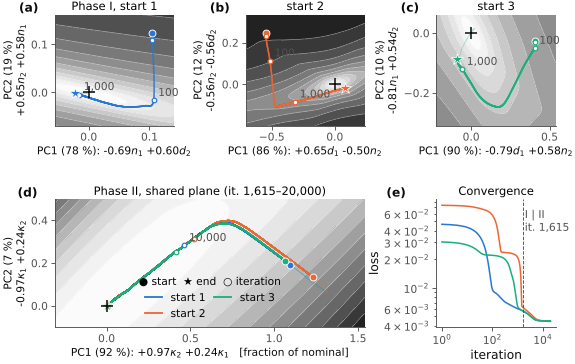

In [8]:
MILESTONES = [10, 100, 1000, 10000]

def draw_path(ax, a, bb, color, lw=1.1, offset=0, milestones=MILESTONES, star=True, annotate=True, zorder=5):
    pts = np.column_stack([a, bb]).reshape(-1, 1, 2)
    seg = np.concatenate([pts[:-1], pts[1:]], axis=1)
    cols = [plt.matplotlib.colors.to_rgba(color, al) for al in np.linspace(0.35, 1.0, max(len(seg), 1))]
    ax.add_collection(LineCollection(seg, colors=cols, linewidths=lw, zorder=zorder, capstyle='round'))
    ax.plot(a[0], bb[0], 'o', color=color, ms=4.5, mec='white', mew=0.6, zorder=zorder + 1)
    if star:
        ax.plot(a[-1], bb[-1], '*', color=color, ms=8, mec='white', mew=0.5, zorder=zorder + 2)
    for m in milestones:
        i = m - offset
        if 0 < i < len(a) - 1:
            ax.plot(a[i], bb[i], 'o', color='white', ms=3, mec=color, mew=0.8, zorder=zorder + 1)
            if annotate and m >= 100:          # the '10' label would overlap the start marker (outside review loop 2, item 22)
                ax.annotate(f'{m:,}', (a[i], bb[i]), xytext=(3, 3), textcoords='offset points', fontsize=7, color=ps.INK2, zorder=zorder + 3)

def short_dir(vec, k=2):
    vec = np.asarray(vec) / np.linalg.norm(vec); idx = np.argsort(-np.abs(vec))[:k]
    return ' '.join(f'{vec[i]:+.2f}{PARAM_TEX[PARAM_NAMES[i]]}' for i in idx)

fig = plt.figure(figsize=ps.figsize(1.0, height_cm=8.8))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15], hspace=0.62, wspace=0.6, left=0.09, right=0.985, top=0.93, bottom=0.11)
vmin = min(g['Z'].min() for g in grids1); vmax = max(g['Z'].max() for g in grids1)
for k, (g, t) in enumerate(zip(grids1, trajs)):
    ax = fig.add_subplot(gs[0, k]); c = lv.TRAJ_COLORS[k]
    cf = lv._landscape(ax, g['a'], g['b'], g['Z'], cbar=False, vmin=vmin, vmax=vmax)
    a, bb, _ = lv.project(g['plane'], t['params'])
    ax.plot(a, bb, color=c, lw=0.6, alpha=0.3, zorder=4)                      # Phase II remainder, faint
    draw_path(ax, a[:b + 1], bb[:b + 1], c)
    ax.plot(0, 0, '+', color=ps.INK, ms=8, mew=1.0, zorder=20)
    ev = g['plane']['explained'] * 100
    ax.set_xlabel(f'PC1 ({ev[0]:.0f} %): {short_dir(g["plane"]["u"])}', fontsize=7)
    ax.set_ylabel(f'PC2 ({ev[1]:.0f} %)\n{short_dir(g["plane"]["v"])}', fontsize=7)
    ax.set_title(f'Phase I, start {k+1}' if k == 0 else f'start {k+1}', fontsize=7.5)
    ax.set_xlim(g['a'][0], g['a'][-1]); ax.set_ylim(g['b'][0], g['b'][-1])
    ax.tick_params(labelsize=7); ax.locator_params(nbins=3)
    ps.panel_label(ax, 'abc'[k], x=-0.3, y=1.0)
ax = fig.add_subplot(gs[1, :2])
lv._landscape(ax, grid2['a'], grid2['b'], grid2['Z'], cbar=False)
for k, t in enumerate(trajs):
    a, bb, _ = lv.project(plane2, t['params'])
    ax.plot(a, bb, color=lv.TRAJ_COLORS[k], lw=0.6, alpha=0.3, zorder=4)
    draw_path(ax, a[b:], bb[b:], lv.TRAJ_COLORS[k], offset=b, annotate=(k == 0))
    ax.plot([], [], color=lv.TRAJ_COLORS[k], lw=1.2, label=f'start {k+1}')
ax.plot(0, 0, '+', color=ps.INK, ms=8, mew=1.0, zorder=20)
ev = plane2['explained'] * 100
ax.set_xlabel(f'PC1 ({ev[0]:.0f} %): {short_dir(plane2["u"], 2)}   [fraction of nominal]', fontsize=7)
ax.set_ylabel(f'PC2 ({ev[1]:.0f} %)\n{short_dir(plane2["v"], 2)}', fontsize=7)
ax.set_title(f'Phase II, shared plane (it. {b:,}–{N:,})', fontsize=7.5)
ax.set_xlim(grid2['a'][0], grid2['a'][-1]); ax.set_ylim(grid2['b'][0], grid2['b'][-1])
ax.legend(loc='lower center', fontsize=7, title='● start  ★ end  ○ iteration', title_fontsize=7, ncol=2, columnspacing=0.8)
ax.tick_params(labelsize=7); ax.locator_params(nbins=5)
ps.panel_label(ax, 'd', x=-0.12, y=1.0)
ax = fig.add_subplot(gs[1, 2])
for k, t in enumerate(trajs):
    ax.plot(np.arange(1, len(t['loss']) + 1), t['loss'], color=lv.TRAJ_COLORS[k], lw=1.0, label=f'start {k+1}')
ax.set(xscale='log', yscale='log', xlabel='iteration', ylabel='loss'); ax.tick_params(labelsize=7)
ax.axvline(b, color=ps.INK2, lw=0.6, ls='--'); ax.text(b * 1.2, ax.get_ylim()[1] * 0.8, f'I | II\nit. {b:,}', fontsize=7, color=ps.INK2, va='top')
ax.set_title('Convergence', fontsize=7.5); ps.despine(ax)
ps.panel_label(ax, 'e', x=-0.42, y=1.0)
ps.savefig(fig, '../figs/fig4_adam_two_phase')
plt.show()

## 8. Figure 3 — measured pulses, fit (start 1), residual vs $\pm\sigma$, amplitude spectra

saved ../figs/fig3_exp_fit.png + .pdf  [13.20 x 7.58 cm; placed at 13.3 cm the smallest font prints at 7.05 pt]


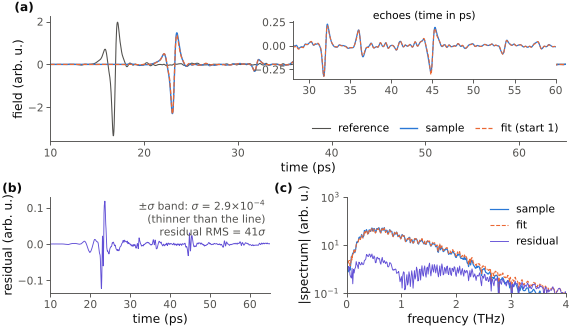

In [9]:
y_fit = P.ysim_np(fits[0]); y_init = P.ysim_np(STARTS[0])
resid1 = true_x_exp - y_fit
fig = plt.figure(figsize=ps.figsize(1.0, height_cm=7.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.5, wspace=0.35, left=0.09, right=0.985, top=0.96, bottom=0.12)
ax = fig.add_subplot(gs[0, :])
ax.plot(t_r, x_exp, color=ps.ROLE['reference'], lw=0.7, label='reference')
ax.plot(t_r, true_x_exp, color=ps.ROLE['sample'], lw=0.9, label='sample')
ax.plot(t_r, y_fit, color=ps.ROLE['fit'], lw=0.8, ls='--', label='fit (start 1)')
ax.set_xlim(10, 65); ax.set_ylabel('field (arb. u.)'); ax.set_xlabel('time (ps)')
ax.legend(loc='lower right', ncol=3, columnspacing=1.0)
axin = ax.inset_axes([0.47, 0.5, 0.51, 0.46], facecolor='white')
m = (t_r > 28) & (t_r < 60)
axin.plot(t_r[m], true_x_exp[m], color=ps.ROLE['sample'], lw=0.8)
axin.plot(t_r[m], y_fit[m], color=ps.ROLE['fit'], lw=0.7, ls='--')
axin.set_xlim(28, 60); axin.tick_params(labelsize=7); axin.set_title('echoes (time in ps)', fontsize=7, pad=1)
axin.locator_params(axis='y', nbins=3)
ps.despine(ax); ps.panel_label(ax, 'a', x=-0.07)
ax = fig.add_subplot(gs[1, 0])
ax.plot(t_r, resid1, color=ps.ROLE['residual'], lw=0.6, label='residual')
ax.axhspan(-sigma, sigma, color=ps.NEUTRAL, alpha=0.4, lw=0)
ax.set_xlim(10, 65); ax.set_xlabel('time (ps)'); ax.set_ylabel('residual (arb. u.)')
rms1 = float(np.sqrt(np.mean(resid1 ** 2)))
ax.text(0.98, 0.98, f'$\\pm\\sigma$ band: $\\sigma$ = {sigma*1e4:.1f}$\\times10^{{-4}}$\n(thinner than the line)\nresidual RMS = {rms1/sigma:.0f}$\\sigma$', transform=ax.transAxes,
        ha='right', va='top', fontsize=7, color=ps.INK2)
ps.despine(ax); ps.panel_label(ax, 'b', x=-0.22)
ax = fig.add_subplot(gs[1, 1])
S_sam = np.abs(np.fft.rfft(true_x_exp)); S_fit = np.abs(np.fft.rfft(y_fit)); S_res = np.abs(np.fft.rfft(resid1))
ax.semilogy(P.f_THz, S_sam, color=ps.ROLE['sample'], lw=0.8, label='sample')
ax.semilogy(P.f_THz, S_fit, color=ps.ROLE['fit'], lw=0.7, ls='--', label='fit')
ax.semilogy(P.f_THz, S_res, color=ps.ROLE['residual'], lw=0.6, label='residual')
ax.set_xlim(0, 4); ax.set_ylim(1e-1, 1e3); ax.set_xlabel('frequency (THz)'); ax.set_ylabel('|spectrum| (arb. u.)')
ax.legend(loc='upper right'); ps.despine(ax); ps.panel_label(ax, 'c', x=-0.33)
ps.savefig(fig, '../figs/fig3_exp_fit')
plt.show()

## 9. Figure — sensitivity spectrum and eigenvector composition

saved ../figs/fig_sensitivity.png + .pdf  [13.29 x 4.14 cm; placed at 13.3 cm the smallest font prints at 7.01 pt]


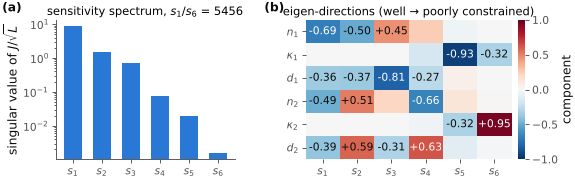

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=ps.figsize(1.0, height_cm=4.6), gridspec_kw=dict(width_ratios=[1, 1.25], wspace=0.35, left=0.1, right=0.98, top=0.9, bottom=0.2))
ax1.bar(range(6), sv, color=ps.BLUE, width=0.6)
ax1.set_yscale('log'); ax1.set_xticks(range(6)); ax1.set_xticklabels([f'$s_{i+1}$' for i in range(6)])
ax1.set_ylabel('singular value of $J/\\sqrt{L}$'); ax1.set_title(f'sensitivity spectrum, $s_1/s_6$ = {sv[0]/sv[-1]:.0f}', fontsize=7.5)
ps.despine(ax1)
im = ax2.imshow(V, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax2.set_xticks(range(6)); ax2.set_xticklabels([f'$s_{i+1}$' for i in range(6)])
ax2.set_yticks(range(6)); ax2.set_yticklabels([PARAM_TEX[n] for n in PARAM_NAMES])
for i in range(6):
    for j in range(6):
        if abs(V[i, j]) > 0.25:
            ax2.text(j, i, f'{V[i, j]:+.2f}', ha='center', va='center', fontsize=7, color='white' if abs(V[i, j]) > 0.6 else ps.INK)
cb = fig.colorbar(im, ax=ax2, fraction=0.05, pad=0.03); cb.outline.set_visible(False); cb.set_label('component')
ax2.set_title('eigen-directions (well → poorly constrained)', fontsize=7.5)
for s in ax2.spines.values(): s.set_visible(False)
ps.panel_label(ax1, 'a', x=-0.3, y=1.04); ps.panel_label(ax2, 'b', x=-0.2, y=1.04)
ps.savefig(fig, '../figs/fig_sensitivity')
plt.show()

## 10. Save trajectories and planes for nb4, write the results JSON

In [11]:
def plane_arrays(p, tag):
    return {f'{tag}_u': p['u'], f'{tag}_v': p['v'], f'{tag}_w': p['w'], f'{tag}_explained': p['explained'],
            f'{tag}_iter_range': np.array(p['iter_range'] if p['iter_range'] is not None else [-1, -1])}
save = dict(ref=ref, scale=scale, G=G, metric=metric, boundary=np.array(b), sigma=np.array(sigma))
for k, t in enumerate(trajs):
    save[f'traj{k}_params'] = t['params']; save[f'traj{k}_loss'] = t['loss']
for k, (p, g) in enumerate(zip(planes1, grids1)):
    save.update(plane_arrays(p, f'plane1_{k}')); save[f'grid1_{k}_a'] = g['a']; save[f'grid1_{k}_b'] = g['b']; save[f'grid1_{k}_Z'] = g['Z']
save.update(plane_arrays(plane2, 'plane2')); save['grid2_a'] = grid2['a']; save['grid2_b'] = grid2['b']; save['grid2_Z'] = grid2['Z']
np.savez('../results/nb3_trajectories.npz', **save)
print('wrote ../results/nb3_trajectories.npz')

def row(p, loss):
    return dict(n1=p[0], k1=p[1], d1_um=p[2] * 1e6, n2=p[3], k2=p[4], d2_um=p[5] * 1e6, n1d1_mm=p[0] * p[2] * 1e3, n2d2_mm=p[3] * p[5] * 1e3, loss=loss)

def thin(a, step=100):
    a = np.asarray(a); idx = np.unique(np.concatenate([np.arange(0, len(a), step), [len(a) - 1]]))
    return dict(iteration=(idx + 1).tolist(), loss=a[idx].tolist())

results = dict(
    notebook='nb3_quartz_si_adam_landscape.ipynb',
    data=dict(reference='data/Reference_15min_nitrogen.txt', sample='data/Quartz_Si_15min_nitrogen.txt', L=L, dt_fs=deltat * 1e15,
              window_ps=float(t_r[-1]), sigma_prepulse=sigma, prepulse_window_ps=P.prepulse_ps, sample_peak=float(np.abs(true_x_exp).max()),
              peak_over_sigma=float(np.abs(true_x_exp).max() / sigma)),
    protocol=dict(loss='MAE + log-cosh (time domain)', optimizer='Adam', lr=LR, iterations=N_ITERS, parametrisation='multiplicative factors u = p/p_start',
                  precision='float64', starts=[row(s, initial_loss[k]) for k, s in enumerate(STARTS)],
                  wall_time_s=walls, ms_per_iteration=[1e3 * w / N_ITERS for w in walls]),
    fits=[row(fits[k], final_losses[k]) for k in range(3)],
    fits_mae=[P.mae_np(fits[k]) for k in range(3)],
    best=dict(start=best_start + 1, **row(ref, loss_ref), mae=mae_ref, mae_over_sigma=mae_ref / sigma),
    spread_between_starts=dict(n1=float(np.ptp(fits[:, 0])), d1_um=float(np.ptp(fits[:, 2]) * 1e6), n2=float(np.ptp(fits[:, 3])), d2_um=float(np.ptp(fits[:, 5]) * 1e6),
                               k1=float(np.ptp(fits[:, 1])), k2=float(np.ptp(fits[:, 4]))),
    loss_history=[thin(t['loss']) for t in trajs],
    loss_at_iteration={str(it): [float(t['loss'][it - 1]) for t in trajs] for it in (1, 10, 100, 1000, 1500, 2000, 5000, 10000, 20000) if it <= N},
    constrained_softplus=dict(beta=BETA_SOFTPLUS, map='kappa = kappa0 * softplus(beta*theta)/softplus(beta), theta starts at 1', start=1,
                              iterations=N_ITERS, wall_time_s=wall_c, **row(pr_c[-1], lo_c[-1]), mae=P.mae_np(pr_c[-1]),
                              loss_increase_percent=100 * (lo_c[-1] / loss_ref - 1),
                              shift_vs_unconstrained_percent=dict(n1=100 * (pr_c[-1][0] / ref[0] - 1), d1=100 * (pr_c[-1][2] / ref[2] - 1),
                                                                  n2=100 * (pr_c[-1][3] / ref[3] - 1), d2=100 * (pr_c[-1][5] / ref[5] - 1),
                                                                  n1d1=100 * (pr_c[-1][0] * pr_c[-1][2] / (ref[0] * ref[2]) - 1),
                                                                  n2d2=100 * (pr_c[-1][3] * pr_c[-1][5] / (ref[3] * ref[5]) - 1))),
    sensitivity=dict(coordinates='x_i = (p_i - p_opt_i)/scale_i, scale = nominal (mean initial guess)', scale=dict(zip(PARAM_NAMES, scale)),
                     G=G, singular_values=sv, eigenvectors_columns=V, ratio_s1_s6=sv[0] / sv[-1], correlation=corr,
                     corr_n1_d1=corr[0, 2], corr_n2_d2=corr[3, 5], corr_k1_k2=corr[1, 4], sqrt_diag_G=dG,
                     visibility_relative_to_n1=dict(k1=dG[0] / dG[1], k2=dG[0] / dG[4])),
    cramer_rao=dict(sigma=sigma, J_column_norms_scaled=col_norms, J_column_norms_physical=col_norms_phys, JtJ_inv_diag=np.diag(JtJ_inv),
                    bound_fraction_of_nominal=dict(zip(PARAM_NAMES, cr_scaled)), bound_physical=dict(zip(PARAM_NAMES, cr_phys)),
                    bound_d1_nm=cr_phys[2] * 1e9, bound_d2_nm=cr_phys[5] * 1e9,
                    bound_k1_percent_of_value=100 * cr_phys[1] / ref[1], bound_k2_percent_of_start=100 * cr_phys[4] / STARTS[0][4],
                    kappa2_fitted=k2_fit, kappa2_bound=k2_bound, kappa2_abs_over_bound=abs(k2_fit) / k2_bound,
                    correlation_of_estimates=corr_cov, rho_n1_d1=corr_cov[0, 2], rho_n2_d2=corr_cov[3, 5],
                    loss_increase_when_k2_set_to_zero_percent=100 * (lo_c[-1] / loss_ref - 1),
                    residual=dict(mae=float(np.mean(np.abs(resid))), mae_over_sigma=float(np.mean(np.abs(resid)) / sigma),
                                  rms=float(np.sqrt(np.mean(resid ** 2))), prepulse_rms=float(np.sqrt(np.mean(resid[t_r < 10] ** 2))))),
    two_phase=dict(frac=FRAC, boundary_iteration=b, n_iterations=N, fraction_in_phase2=(N - b) / N, grid_res=RES,
                   loss_at_boundary=[float(t['loss'][b]) for t in trajs], loss_drop_phase1_percent=[100 * (1 - t['loss'][b] / t['loss'][0]) for t in trajs],
                   loss_drop_phase2_percent=[100 * (1 - t['loss'][-1] / t['loss'][b]) for t in trajs],
                   phase1_planes=[dict(start=k + 1, explained=p['explained'], u=p['u'], v=p['v'], w=p['w']) for k, p in enumerate(planes1)],
                   phase2_plane=dict(explained=plane2['explained'], u=plane2['u'], v=plane2['v'])),
)
json.dump(ps.to_jsonable(results), open('../results/nb3.json', 'w'), indent=1)
print('wrote ../results/nb3.json')

wrote ../results/nb3_trajectories.npz
wrote ../results/nb3.json


# Loop-1 checks (domain review of 2026-11-24)

* **C14** (quartz/Si traces) pre-pulse noise: white component from first differences of quiet segments, autocorrelation.
* **C5** $|\kappa_2|$/bound at the Adam best point and at the converged rMSE optimum under several noise models:
  canonical σ (R12); white σ from first differences; generalised Fisher $(J^\top C^{-1}J)^{-1}$ with $C$ the Toeplitz matrix of the
  pre-pulse autocovariance; residual-scaled bound; residual sandwich (HAC, Bartlett 1 ps / 3 ps); moving-block bootstrap of the
  residuals (block 1 ps, 100 resamples, rMSE L-BFGS warm-started).
* **C6** CR bounds of $d_1$, $d_2$ with and without a free reference delay τ and amplitude $a$; the thickness-transfer direction
  ($d_1\uparrow d_2\downarrow$ at constant $n_1d_1$, $n_2d_2$) and the κ-split direction compared with the eigen-directions of $G$.
* **C8** Adam from start 1 continued to $6\times10^4$ iterations: loss, κ₂, d₁, d₂, gradient norm at 2…6 × 10⁴.
* Mini-table of the singular values $s_k$ of $J/\sqrt L$ (nominal-scaled coordinates) and their dominant parameter combinations.

In [12]:
from loop1_tools import noise_stats, prepulse_acf, toeplitz_from_acf, gls_cov, sandwich_cov, cr_from_J, moving_block_bootstrap, lbfgs_minimize, grad_norm, jacobian_tau_amp
import copy
LOOP1 = dict(date='2026-11-24', source='reviews/loop1_domain.md section 5'); T_LOOP1 = {}
N_SI_LIT = 3.4175
# ---- C14 (quartz/Si traces)
ns_sam = noise_stats(t_r, true_x_exp); ns_ref = noise_stats(t_r, x_exp)
LOOP1['C14_noise_quartzSi'] = dict(sample=ns_sam, reference=ns_ref)
print(f"sample trace: sigma (0-10 ps) {ns_sam['std_0_10ps']:.2e}; white (first differences) min {ns_sam['white_min']:.2e}, median {ns_sam['white_median']:.2e}; "
      f"ACF 1/e {ns_sam['acf_1_over_e_ps']:.2f} ps, integrated correlation time {ns_sam['integrated_corr_time_ps']:.2f} ps")

# ---- C5: the converged least-squares (rMSE) optimum, warm-started from the Adam best point
ref_t = torch.tensor(ref, dtype=DT)
f_rmse = lambda u, P_=P: P_.loss_torch(u * ref_t, 'rmse')
t0 = time.time()
u_r, l_r, nev_r = lbfgs_minimize(f_rmse, np.ones(6), max_iter=1500)
p_rmse = u_r * ref
print(f"rMSE optimum ({nev_r} evaluations, {time.time()-t0:.0f} s): " + ', '.join(f'{nm} {v:.6g}' for nm, v in zip(PARAM_NAMES, p_rmse)) +
      f"; rMSE {l_r:.6e}; |grad| {grad_norm(f_rmse, u_r)[0]:.2e}")

def bounds_all_models(p, tag):
    """|kappa_2| / bound and n_2 - 3.4175 / bound at point p for several noise models (physical units)."""
    Jp = P.jacobian(p, scale); res_p = true_x_exp - P.ysim_np(p); rms = float(np.sqrt(np.mean(res_p ** 2)))
    A = np.linalg.inv(Jp.T @ Jp)
    covs = {'canonical_sigma_R12': sigma ** 2 * A,
            'white_min_first_difference': ns_sam['white_min'] ** 2 * A,
            'white_median_first_difference': ns_sam['white_median'] ** 2 * A,
            'gls_prepulse_toeplitz': gls_cov(Jp, toeplitz_from_acf(prepulse_acf(true_x_exp, t_r), L, nugget=1e-3 * sigma ** 2)),
            'residual_rms_scaled': rms ** 2 * A}
    r_acf = np.correlate(res_p, res_p, 'full')[L - 1:] / L
    for lag_ps in (1.0, 3.0):
        covs[f'sandwich_HAC_bartlett_{lag_ps:g}ps'] = sandwich_cov(Jp, toeplitz_from_acf(r_acf, L, taper_lags=int(round(lag_ps * 1e-12 / deltat))))
    out = {}
    for k_, cv in covs.items():
        b_ = np.sqrt(np.diag(cv)) * scale
        out[k_] = dict(bounds=dict(zip(PARAM_NAMES, b_)), k2_abs_over_bound=abs(p[4]) / b_[4], n2_minus_lit_over_bound=(p[3] - N_SI_LIT) / b_[3],
                       d1_bound_nm=b_[2] * 1e9, d2_bound_nm=b_[5] * 1e9)
    print(f"\n{tag}: kappa_2 = {p[4]:+.4e}, n_2 = {p[3]:.5f}, residual RMS = {rms:.3e} = {rms/sigma:.1f} sigma(R12)")
    for k_, o in out.items():
        print(f"   {k_:34s} kappa_2 bound {o['bounds']['k2']:.2e} -> |kappa_2|/bound {o['k2_abs_over_bound']:8.1f};  (n_2 - 3.4175)/bound {o['n2_minus_lit_over_bound']:8.1f}")
    return dict(point=dict(zip(PARAM_NAMES, p)), residual_rms=rms, residual_rms_over_sigma=rms / sigma, models=out)

c5 = dict(adam_best=bounds_all_models(ref, 'Adam best point (nb3, start 3, MAE + log-cosh)'),
          rmse_optimum=bounds_all_models(p_rmse, 'converged rMSE optimum'))
c5['rmse_optimum']['lbfgs_evaluations'] = nev_r; c5['rmse_optimum']['rmse'] = l_r

# moving-block bootstrap of the residuals at the rMSE optimum (least-squares estimator), block 1 ps
N_BOOT, BLOCK = 100, int(round(1e-12 / deltat))
y_hat = P.ysim_np(p_rmse); r_hat = true_x_exp - y_hat
rng_bs = np.random.default_rng(5)
Pb = copy.copy(P)
boot = []
t0 = time.time()
for ib_ in range(N_BOOT):
    Pb.y_true = torch.tensor(y_hat + moving_block_bootstrap(r_hat, BLOCK, rng_bs), dtype=DT)
    ub, lb, nb_ = lbfgs_minimize(lambda u: Pb.loss_torch(u * torch.tensor(p_rmse, dtype=DT), 'rmse'), np.ones(6), max_iter=300)
    boot.append(ub * p_rmse)
boot = np.array(boot); T_LOOP1['C5_bootstrap_s'] = time.time() - t0
bs_std = boot.std(axis=0, ddof=1)
c5['block_bootstrap'] = dict(n_resamples=N_BOOT, block_samples=BLOCK, block_ps=BLOCK * deltat * 1e12, point='rmse_optimum',
                             std=dict(zip(PARAM_NAMES, bs_std)), mean=dict(zip(PARAM_NAMES, boot.mean(axis=0))),
                             k2_abs_over_std=abs(p_rmse[4]) / bs_std[4], n2_minus_lit_over_std=(p_rmse[3] - N_SI_LIT) / bs_std[3],
                             fraction_k2_negative=float(np.mean(boot[:, 4] < 0)),
                             d1_range_um=[boot[:, 2].min() * 1e6, boot[:, 2].max() * 1e6], wall_time_s=T_LOOP1['C5_bootstrap_s'])
print(f"\nblock bootstrap ({N_BOOT} x, block {BLOCK} samples = {BLOCK*deltat*1e12:.2f} ps, {T_LOOP1['C5_bootstrap_s']:.0f} s): std kappa_2 {bs_std[4]:.2e} -> |kappa_2|/std "
      f"{abs(p_rmse[4])/bs_std[4]:.1f}; std d1 {bs_std[2]*1e9:.0f} nm, d2 {bs_std[5]*1e9:.0f} nm; std n2 {bs_std[3]:.1e}; kappa_2 < 0 in {100*np.mean(boot[:,4]<0):.0f} % of resamples")
LOOP1['C5_kappa2_vs_noise_models'] = c5

sample trace: sigma (0-10 ps) 2.90e-04; white (first differences) min 4.51e-05, median 4.77e-05; ACF 1/e 0.76 ps, integrated correlation time 2.22 ps


rMSE optimum (2173 evaluations, 12 s): n1 1.99678, k1 0.00777576, d1 0.000977709, n2 3.30372, k2 -0.00727442, d2 0.000398136; rMSE 1.123980e-02; |grad| 3.94e-06



Adam best point (nb3, start 3, MAE + log-cosh): kappa_2 = -1.4578e-03, n_2 = 3.44761, residual RMS = 1.199e-02 = 41.3 sigma(R12)
   canonical_sigma_R12                kappa_2 bound 1.90e-05 -> |kappa_2|/bound     76.8;  (n_2 - 3.4175)/bound    107.8
   white_min_first_difference         kappa_2 bound 2.95e-06 -> |kappa_2|/bound    493.4;  (n_2 - 3.4175)/bound    692.5
   white_median_first_difference      kappa_2 bound 3.12e-06 -> |kappa_2|/bound    467.2;  (n_2 - 3.4175)/bound    655.7
   gls_prepulse_toeplitz              kappa_2 bound 1.60e-05 -> |kappa_2|/bound     91.0;  (n_2 - 3.4175)/bound     89.4
   residual_rms_scaled                kappa_2 bound 7.84e-04 -> |kappa_2|/bound      1.9;  (n_2 - 3.4175)/bound      2.6
   sandwich_HAC_bartlett_1ps          kappa_2 bound 2.04e-03 -> |kappa_2|/bound      0.7;  (n_2 - 3.4175)/bound      0.9
   sandwich_HAC_bartlett_3ps          kappa_2 bound 2.20e-03 -> |kappa_2|/bound      0.7;  (n_2 - 3.4175)/bound      0.7



converged rMSE optimum: kappa_2 = -7.2744e-03, n_2 = 3.30372, residual RMS = 1.124e-02 = 38.7 sigma(R12)
   canonical_sigma_R12                kappa_2 bound 1.96e-05 -> |kappa_2|/bound    372.0;  (n_2 - 3.4175)/bound   -424.7
   white_min_first_difference         kappa_2 bound 3.04e-06 -> |kappa_2|/bound   2390.1;  (n_2 - 3.4175)/bound  -2728.8
   white_median_first_difference      kappa_2 bound 3.21e-06 -> |kappa_2|/bound   2263.2;  (n_2 - 3.4175)/bound  -2584.0
   gls_prepulse_toeplitz              kappa_2 bound 1.63e-05 -> |kappa_2|/bound    446.8;  (n_2 - 3.4175)/bound   -349.5
   residual_rms_scaled                kappa_2 bound 7.58e-04 -> |kappa_2|/bound      9.6;  (n_2 - 3.4175)/bound    -11.0
   sandwich_HAC_bartlett_1ps          kappa_2 bound 1.91e-03 -> |kappa_2|/bound      3.8;  (n_2 - 3.4175)/bound     -3.8
   sandwich_HAC_bartlett_3ps          kappa_2 bound 2.04e-03 -> |kappa_2|/bound      3.6;  (n_2 - 3.4175)/bound     -3.3



block bootstrap (100 x, block 30 samples = 0.99 ps, 160 s): std kappa_2 1.67e-03 -> |kappa_2|/std 4.4; std d1 3279 nm, d2 3330 nm; std n2 2.8e-02; kappa_2 < 0 in 99 % of resamples


In [13]:
# ---- C6: CR bounds with a free reference delay tau and amplitude a; thickness-transfer and kappa-split directions
J_ta = jacobian_tau_amp(P.fwd, ref[[0, 3]], ref[[1, 4]], ref[[2, 5]])        # columns n1 n2 k1 k2 d1 d2 tau a
c6 = {}
for tag, cols in (('without_tau_a', list(range(6))), ('with_tau_a', list(range(8)))):
    cov, bnd = cr_from_J(J_ta[:, cols], sigma)
    g = lambda idx_w: (lambda v: float(np.sqrt(v @ cov @ v)))(np.array([idx_w.get(c, 0.0) for c in range(len(cols))]))
    c6[tag] = dict(d1_nm=bnd[4] * 1e9, d2_nm=bnd[5] * 1e9, n1=bnd[0], n2=bnd[1], k1=bnd[2], k2=bnd[3],
                   d1_plus_d2_nm=g({4: 1, 5: 1}) * 1e9, n1d1_nm=g({0: ref[2], 4: ref[0]}) * 1e9, n2d2_nm=g({1: ref[5], 5: ref[3]}) * 1e9,
                   tau_fs=(bnd[6] * 1e15 if len(cols) > 6 else None), a=(bnd[7] if len(cols) > 6 else None))
    print(f"C6 quartz/Si CR {tag:14s}: d1 {c6[tag]['d1_nm']:.1f} nm, d2 {c6[tag]['d2_nm']:.1f} nm, d1+d2 {c6[tag]['d1_plus_d2_nm']:.1f} nm, "
          f"n1d1 {c6[tag]['n1d1_nm']:.1f} nm, n2d2 {c6[tag]['n2d2_nm']:.1f} nm, n1 {c6[tag]['n1']:.1e}, n2 {c6[tag]['n2']:.1e}, |k2|/bound {abs(ref[4])/c6[tag]['k2']:.0f}"
          + (f", tau {c6[tag]['tau_fs']:.2f} fs, a {c6[tag]['a']:.1e}" if c6[tag]['tau_fs'] else ''))
# directions in nominal-scaled coordinates x = dp / scale (PARAM order n1 k1 d1 n2 k2 d2)
n1, k1, d1, n2, k2, d2 = ref
v_tt = np.array([-n1 / d1, 0, 1, n2 / d2, 0, -1]) / scale          # d1 up, d2 down at constant n1 d1, n2 d2 (=> d1 + d2 constant)
v_ks = np.array([0, 1 / d1, 0, 0, -1 / d2, 0]) / scale            # kappa1 d1 + kappa2 d2 constant
v_tt /= np.linalg.norm(v_tt); v_ks /= np.linalg.norm(v_ks)
cos_tt = V.T @ v_tt; cos_ks = V.T @ v_ks
stiff = lambda v: float(np.linalg.norm(J @ v) / np.sqrt(L))       # RMS pulse change per unit step along v (compare with s_k)
def disp_fraction(pa, pb):
    dx = (np.asarray(pb) - np.asarray(pa)) / scale; nrm = np.linalg.norm(dx)
    Bm = np.column_stack([v_tt, v_ks]); coef, *_ = np.linalg.lstsq(Bm, dx, rcond=None)
    nd = [0, 2, 3, 5]; dxn = dx[nd]; vtn = v_tt[nd] / np.linalg.norm(v_tt[nd])
    return dict(norm=nrm, cos_tt=float(dx @ v_tt / nrm), cos_ks=float(dx @ v_ks / nrm), fraction_in_span=float(np.linalg.norm(Bm @ coef) ** 2 / nrm ** 2),
                cos_tt_in_n_d_subspace=float(dxn @ vtn / np.linalg.norm(dxn)),
                delta_d1_um=(pb[2] - pa[2]) * 1e6, delta_d2_um=(pb[5] - pa[5]) * 1e6)
disp = {'adam_best_to_softplus': disp_fraction(ref, pr_c[-1]), 'adam_best_to_rmse_optimum': disp_fraction(ref, p_rmse),
        'adam_fit1_to_adam_fit2': disp_fraction(fits[0], fits[1])}
print('\ncosine of the thickness-transfer direction with the eigen-directions s1..s6:', np.round(cos_tt, 3))
print('cosine of the kappa-split direction with the eigen-directions s1..s6     :', np.round(cos_ks, 3))
print(f'stiffness along the transfer direction {stiff(v_tt):.4f}, along the kappa split {stiff(v_ks):.4f}  (s5 = {sv[4]:.4f}, s6 = {sv[5]:.4f})')
for k_, dd in disp.items():
    print(f"   {k_:28s}: |dx| {dd['norm']:.2e}, cos with transfer {dd['cos_tt']:+.3f}, with kappa split {dd['cos_ks']:+.3f}, fraction in span {dd['fraction_in_span']:.3f}; "
          f"d1 {dd['delta_d1_um']:+.2f} um, d2 {dd['delta_d2_um']:+.2f} um; (n, d) part along the transfer direction: cos {dd['cos_tt_in_n_d_subspace']:+.4f}")
LOOP1['C6_tau_amp_and_valley_directions'] = dict(
    sigma=sigma, point='Adam best point (start 3)', cramer_rao=c6,
    thickness_transfer_direction=dict(definition='d1 up, d2 down at constant n1 d1 and n2 d2, in nominal-scaled coordinates', vector=v_tt,
                                      cos_with_eigenvectors_s1_to_s6=cos_tt, stiffness_rms_per_unit_step=stiff(v_tt)),
    kappa_split_direction=dict(definition='kappa1 d1 + kappa2 d2 constant', vector=v_ks, cos_with_eigenvectors_s1_to_s6=cos_ks, stiffness_rms_per_unit_step=stiff(v_ks)),
    singular_values=sv, end_point_displacements=disp)

# ---- singular-value mini-table (labelled)
def combo(vec, thr=0.25):
    idx = [i for i in np.argsort(-np.abs(vec)) if abs(vec[i]) >= thr]
    s0 = np.sign(vec[idx[0]]); return ' '.join(f'{s0*vec[i]:+.2f} {PARAM_NAMES[i]}' for i in idx)
sv_table = [dict(k=k + 1, s_k=float(sv[k]), eigenvalue_of_G=float(sv[k] ** 2), s_k_over_s1=float(sv[k] / sv[0]), combination=combo(V[:, k]),
                 components=dict(zip(PARAM_NAMES, V[:, k]))) for k in range(6)]
for r_ in sv_table:
    print(f"s{r_['k']} = {r_['s_k']:.4g}  ({r_['combination']})")
LOOP1['singular_value_table'] = dict(
    label='singular values s_k of J/sqrt(L) (= square roots of the eigenvalues of G = J^T J / L), J = dy/dx in nominal-scaled coordinates x_i = (p_i - p_i^opt)/p_i^nom; '
          'p^nom = mean of the three starts; components of the right singular vector (sign fixed so that the largest component is positive); '
          'listed components |v_i| >= 0.25', nominal_scale=dict(zip(PARAM_NAMES, scale)), rows=sv_table, ratio_s1_s6=float(sv[0] / sv[-1]))

C6 quartz/Si CR without_tau_a : d1 31.6 nm, d2 31.1 nm, d1+d2 7.5 nm, n1d1 8.3 nm, n2d2 5.9 nm, n1 6.1e-05, n2 2.8e-04, |k2|/bound 77
C6 quartz/Si CR with_tau_a    : d1 136.8 nm, d2 52.9 nm, d1+d2 171.6 nm, n1d1 8.3 nm, n2d2 5.9 nm, n1 2.7e-04, n2 4.8e-04, |k2|/bound 71, tau 0.57 fs, a 1.1e-04

cosine of the thickness-transfer direction with the eigen-directions s1..s6: [-0.     0.002 -0.002 -0.985  0.174  0.02 ]
cosine of the kappa-split direction with the eigen-directions s1..s6     : [-0.    -0.     0.    -0.013  0.044 -0.999]
stiffness along the transfer direction 0.0723, along the kappa split 0.0020  (s5 = 0.0192, s6 = 0.0016)
   adam_best_to_softplus       : |dx| 3.03e-01, cos with transfer +0.030, with kappa split -0.999, fraction in span 1.000; d1 +2.38 um, d2 -2.31 um; (n, d) part along the transfer direction: cos +0.9999
   adam_best_to_rmse_optimum   : |dx| 1.13e+00, cos with transfer -0.057, with kappa split +0.998, fraction in span 1.000; d1 -16.51 um, d2 +16.72 um; (n, d)

In [14]:
# ---- C8: Adam from start 1 continued to 6 x 10^4 iterations (same protocol; the first 2 x 10^4 reproduce fit 1)
N_C8 = 60000
t0 = time.time()
pr8, lo8, wall8 = adam_fit(STARTS[0], n_iters=N_C8 + 1, print_step=10000, label='C8, start 1')
T_LOOP1['C8_s'] = wall8
p0_1 = torch.tensor(STARTS[0], dtype=DT)
f_u = lambda u: P.loss_torch(u * p0_1)
c8 = []
CHECK_ITS = [i for i in (N_ITERS - 1, 20000, 30000, 40000, 50000, 60000) if i <= N_C8]
for it in CHECK_ITS:
    p = pr8[it]; gn, _ = grad_norm(f_u, p / STARTS[0])
    c8.append(dict(iteration=it, loss=float(lo8[it]), n1=p[0], k1=p[1], d1_um=p[2] * 1e6, n2=p[3], k2=p[4], d2_um=p[5] * 1e6,
                   n1d1_um=p[0] * p[2] * 1e6, n2d2_um=p[3] * p[5] * 1e6, d1_plus_d2_um=(p[2] + p[5]) * 1e6, k1d1_plus_k2d2_um=(p[1] * p[2] + p[4] * p[5]) * 1e6,
                   grad_norm_u=gn))
print(f"\nC8 ({wall8:.0f} s, {1e3*wall8/N_C8:.2f} ms/it); check: iterate {N_ITERS-1} equals loop-0 fit 1: max |diff| = {np.max(np.abs(pr8[min(N_ITERS-1, N_C8)]-fits[0])):.1e}")
print(f"{'iter':>6} {'loss':>11} {'k2':>11} {'d1/um':>9} {'d2/um':>9} {'n2':>8} {'|grad_u|':>9}")
for r_ in c8:
    print(f"{r_['iteration']:6d} {r_['loss']:11.5e} {r_['k2']:+11.4e} {r_['d1_um']:9.3f} {r_['d2_um']:9.3f} {r_['n2']:8.5f} {r_['grad_norm_u']:9.2e}")
ia, ib2 = CHECK_ITS[-2], CHECK_ITS[-1]
k2_drift = (pr8[ib2, 4] - pr8[ia, 4]) / max(ib2 - ia, 1)
LOOP1['C8_adam_to_60000'] = dict(start=1, lr=LR, iterations=N_C8, wall_time_s=wall8, checkpoints=c8,
                                 k2_drift_per_1e4_last=float(k2_drift * 1e4), d1_drift_um_per_1e4_last=float((pr8[ib2, 2] - pr8[ia, 2]) * 1e6 * 1e4 / max(ib2 - ia, 1)),
                                 loss_drop_20k_to_end_percent=float(100 * (1 - lo8[N_C8] / lo8[min(20000, N_C8)])),
                                 reproduces_loop0_fit1_max_abs_diff=float(np.max(np.abs(pr8[min(N_ITERS - 1, N_C8)] - fits[0]))))

[C8, start 1] it  10000  n1=1.956825 k1=4.274e-03 d1=997.97um  n2=3.479755 k2=+1.351e-03 d2=377.81um  loss=4.495997e-03


[C8, start 1] it  20000  n1=1.963868 k1=5.407e-03 d1=994.28um  n2=3.447833 k2=-1.444e-03 d2=381.41um  loss=4.452226e-03


[C8, start 1] it  30000  n1=1.963990 k1=5.412e-03 d1=994.19um  n2=3.446866 k2=-1.482e-03 d2=381.49um  loss=4.451698e-03


[C8, start 1] it  40000  n1=1.963971 k1=5.403e-03 d1=994.19um  n2=3.446681 k2=-1.475e-03 d2=381.50um  loss=4.452944e-03


[C8, start 1] it  50000  n1=1.964038 k1=5.405e-03 d1=994.23um  n2=3.446871 k2=-1.476e-03 d2=381.50um  loss=4.452264e-03


[C8, start 1] it  60000  n1=1.964025 k1=5.409e-03 d1=994.21um  n2=3.446809 k2=-1.480e-03 d2=381.49um  loss=4.451748e-03


[C8, start 1] it  60001  n1=1.963994 k1=5.409e-03 d1=994.19um  n2=3.446759 k2=-1.480e-03 d2=381.49um  loss=4.453047e-03



C8 (278 s, 4.64 ms/it); check: iterate 19999 equals loop-0 fit 1: max |diff| = 0.0e+00
  iter        loss          k2     d1/um     d2/um       n2  |grad_u|
 19999 4.45223e-03 -1.4444e-03   994.279   381.405  3.44783  3.49e-02
 20000 4.45220e-03 -1.4445e-03   994.281   381.405  3.44783  3.49e-02
 30000 4.45165e-03 -1.4824e-03   994.196   381.495  3.44689  3.67e-03
 40000 4.45173e-03 -1.4752e-03   994.208   381.509  3.44673  3.90e-03
 50000 4.45177e-03 -1.4757e-03   994.217   381.499  3.44683  9.18e-03
 60000 4.45305e-03 -1.4799e-03   994.192   381.488  3.44676  8.93e-02


### Write the loop-1 results into `results/nb3.json`

In [15]:
LOOP1['timings_s'] = T_LOOP1
LOOP1['figure_export'] = ps.FONT_LOG
results['loop1_checks'] = LOOP1
json.dump(ps.to_jsonable(results), open('../results/nb3.json', 'w'), indent=1)
print('wrote ../results/nb3.json with loop1_checks:', list(LOOP1))

wrote ../results/nb3.json with loop1_checks: ['date', 'source', 'C14_noise_quartzSi', 'C5_kappa2_vs_noise_models', 'C6_tau_amp_and_valley_directions', 'singular_value_table', 'C8_adam_to_60000', 'timings_s', 'figure_export']
